# Medical Simplifier: Privacy vs. Utility Trade-off
Metrics are loaded from `results/redaction_gt.csv`, written by
`python evaluate_pipeline.py redact --detectors mvp regex_ids hybrid`.
Re-run that command and then this notebook to refresh the chart.

       Detector  Clinical Text Destroyed (%)  PII Leakage (%)
   MVP Pipeline                         29.6             34.9
      Regex IDs                          0.0             37.8
Hybrid Pipeline                          0.2              4.6


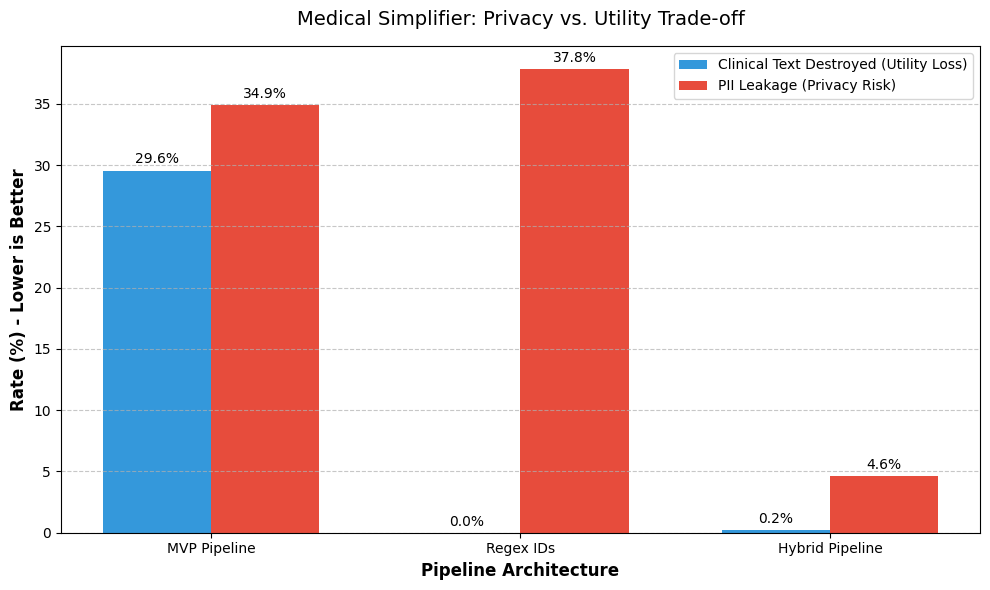

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Per-type counts written by evaluate_pipeline.py (ground-truth text)
results = pd.read_csv('results/redaction_gt.csv')

DISPLAY_NAMES = {'mvp': 'MVP Pipeline', 'regex_ids': 'Regex IDs', 'hybrid': 'Hybrid Pipeline'}


def rate(group):
    """Percentage of readable spans in `group` that were 'bad' (leaked / destroyed), per detector."""
    g = results[results['group'] == group].groupby('detector')[['present', 'bad']].sum()
    return 100 * g['bad'] / g['present']


df = pd.DataFrame({
    'Clinical Text Destroyed (%)': rate('keep'),  # Utility loss (lower is better)
    'PII Leakage (%)': rate('pii'),               # Privacy risk (lower is better)
}).reindex(DISPLAY_NAMES).rename(index=DISPLAY_NAMES).rename_axis('Detector').reset_index()
print(df.round(1).to_string(index=False))

# Set up the figure
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(df['Detector']))
width = 0.35

bars_error = ax.bar(x - width/2, df['Clinical Text Destroyed (%)'], width,
                    label='Clinical Text Destroyed (Utility Loss)', color='#3498db')
bars_leakage = ax.bar(x + width/2, df['PII Leakage (%)'], width,
                      label='PII Leakage (Privacy Risk)', color='#e74c3c')

ax.set_xlabel('Pipeline Architecture', fontsize=12, fontweight='bold')
ax.set_ylabel('Rate (%) - Lower is Better', fontsize=12, fontweight='bold')
ax.set_title('Medical Simplifier: Privacy vs. Utility Trade-off', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df['Detector'])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

ax.bar_label(bars_error, padding=3, fmt='%.1f%%')
ax.bar_label(bars_leakage, padding=3, fmt='%.1f%%')

plt.tight_layout()
plt.show()